In [1]:
#Importamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

### Diccionario de Inicial de Variables – Déficit Habitacional

| Campo | Tipo de dato | Descripción | Información que contiene |
|---|---|---|---|
| `OBJECTID` | int32 | Identificador del objeto geográfico. | Número único asignado a cada registro de la capa espacial. |
| `DPTO_CCDGO` | Object | Código DIVIPOLA del departamento. | Código que identifica el departamento según la codificación DIVIPOLA. |
| `MPIO_CCDGO` | Object | Código DIVIPOLA del municipio. | Código que identifica el municipio según la codificación DIVIPOLA. |
| `MPIO_CNMBR` | Object | Nombre del municipio. | Nombre oficial del municipio al que corresponde el registro. |
| `MPIO_NANO` | int32 | Año de referencia de la información. | Año al que corresponde la información estadística del municipio. |
| `DPTO_CNMBR` | Object | Nombre del departamento. | Nombre del departamento al que pertenece el municipio. |
| `TOTAL_HOGA` | float64 | Total de hogares. | Cantidad total de hogares registrados en el municipio. |
| `N_dvcuanti` | float64 | Número de hogares en déficit habitacional cuantitativo. | Cantidad de hogares que presentan déficit habitacional cuantitativo. |
| `N_dvcuali` | float64 | Número de hogares en déficit habitacional cualitativo. | Cantidad de hogares que presentan déficit habitacional cualitativo. |
| `N_dvhabita` | float64 | Número total de hogares en déficit habitacional (cuantitativo + cualitativo). | Cantidad total de hogares que presentan déficit habitacional, considerando los componentes cuantitativo y cualitativo. |
| `PC_dvcuant` | float64 | Porcentaje de hogares en déficit cuantitativo. | Proporción porcentual de hogares que presentan déficit habitacional cuantitativo. |
| `PC_dvcuali` | float64 | Porcentaje de hogares en déficit cualitativo. | Proporción porcentual de hogares que presentan déficit habitacional cualitativo. |
| `PC_dvhabit` | float64 | Porcentaje total de hogares en déficit habitacional. | Proporción porcentual de hogares que presentan déficit habitacional, considerando sus componentes cuantitativo y cualitativo. |
| `PC_DV_JFHB` | float64 | Porcentaje de déficit habitacional en hogares con jefatura femenina. | Proporción porcentual de hogares con jefatura femenina que presentan déficit habitacional. |
| `PC_DV_JFMJ` | float64 | Porcentaje de déficit habitacional en hogares con jefatura masculina. | Proporción porcentual de hogares con jefatura masculina que presentan déficit habitacional. |
| `N_tipo` | float64 | Número de hogares con déficit por tipo de vivienda inadecuada. | Cantidad de hogares que presentan condiciones inadecuadas relacionadas con el tipo de vivienda. |
| `N_pared` | float64 | Número de hogares con déficit por material inadecuado de paredes. | Cantidad de hogares cuyas viviendas presentan materiales inadecuados en las paredes. |
| `N_cohab` | float64 | Número de hogares en condición de cohabitación. | Cantidad de hogares que presentan condiciones de cohabitación. |
| `N_defhaci` | float64 | Número de hogares con déficit por hacinamiento. | Cantidad de hogares que presentan condiciones de hacinamiento. |
| `N_defhacim` | float64 | Número de hogares con hacinamiento mitigable. | Cantidad de hogares clasificados en la categoría de hacinamiento mitigable. |
| `N_defhac_1` | float64 | Número de hogares con hacinamiento no mitigable. | Cantidad de hogares clasificados en la categoría de hacinamiento no mitigable. |
| `N_pisos` | float64 | Número de hogares con déficit por material inadecuado de pisos. | Cantidad de hogares cuyas viviendas presentan materiales inadecuados en los pisos. |
| `N_pisos_j` | float64 | Número de hogares con déficit en pisos jerarquizado. | Cantidad de hogares clasificados según el déficit en las condiciones de los pisos, mediante la variable jerarquizada. |
| `N_cocina` | float64 | Número de hogares sin cocina adecuada. | Cantidad de hogares que no cuentan con una cocina adecuada en la vivienda. |
| `N_cocina_j` | float64 | Número de hogares sin cocina adecuada jerarquizado. | Cantidad de hogares clasificados según la condición de ausencia de cocina adecuada, mediante la variable jerarquizada. |
| `N_agua` | float64 | Número de hogares sin acceso adecuado a agua. | Cantidad de hogares que no cuentan con acceso adecuado al servicio de agua. |
| `N_agua_j` | float64 | Número de hogares sin acceso adecuado a agua jerarquizado. | Cantidad de hogares clasificados según las condiciones de acceso al agua, mediante la variable jerarquizada. |
| `N_alcantar` | float64 | Número de hogares sin acceso a alcantarillado. | Cantidad de hogares que no cuentan con acceso al servicio de alcantarillado. |
| `N_alcant_1` | float64 | Número de hogares con déficit en alcantarillado jerarquizado. | Cantidad de hogares clasificados según las condiciones de acceso al alcantarillado, mediante la variable jerarquizada. |
| `N_energia` | float64 | Número de hogares sin acceso a energía eléctrica. | Cantidad de hogares que no cuentan con acceso al servicio de energía eléctrica. |
| `N_energia_` | float64 | Número de hogares con déficit en energía jerarquizado. | Cantidad de hogares clasificados según las condiciones de acceso a energía eléctrica, mediante la variable jerarquizada. |
| `N_basura` | float64 | Número de hogares sin servicio adecuado de recolección de basuras. | Cantidad de hogares que no cuentan con un servicio adecuado de recolección de basuras. |
| `N_basura_j` | float64 | Número de hogares sin servicio de basuras jerarquizado. | Cantidad de hogares clasificados según las condiciones del servicio de recolección de basuras, mediante la variable jerarquizada. |
| `Shape_Leng` | float64 | Longitud de la geometría. | Longitud del perímetro del polígono que representa el municipio. |
| `Shape_Area` | float64 | Área de la geometría. | Superficie del polígono que representa el municipio. |
| `Geometry` | geometry | Geometría asociada al municipio. | Objeto geométrico que representa espacialmente el territorio municipal mediante un polígono. |

## Importación de Dataset

In [2]:
gdf = gpd.read_file('Bases/SHP_MPIO_DEFVIV (Geojson).geojson')

In [3]:
gdf_copy=gdf.copy()

In [4]:
gdf_copy.head(5)

,OBJECTID,DPTO_CCDGO,MPIO_CCDGO,MPIO_CNMBR,MPIO_NANO,DPTO_CNMBR,TOTAL_HOGA,N_dvcuanti,N_dvcuali,N_dvhabita,...,N_agua_j,N_alcantar,N_alcant_1,N_energia,N_energia_,N_basura,N_basura_j,Shape_Leng,Shape_Area,geometry
0,1,25,25483,NARIÑO,2017,CUNDINAMARCA,860.0,32.0,350.0,382.0,...,199.0,54.0,52.0,23.0,21.0,4.0,3.0,0.521912,0.004494,"MULTIPOLYGON (((-74.7413 4.47294, -74.74124 4...."
1,2,25,25513,PACHO,2017,CUNDINAMARCA,8856.0,631.0,3285.0,3916.0,...,2254.0,691.0,560.0,305.0,215.0,216.0,190.0,1.202163,0.032840,"MULTIPOLYGON (((-74.21183 5.29443, -74.21167 5..."
2,3,25,25506,VENECIA,2017,CUNDINAMARCA,1521.0,387.0,536.0,923.0,...,323.0,129.0,53.0,141.0,45.0,89.0,82.0,0.487368,0.009952,"MULTIPOLYGON (((-74.44812 4.11888, -74.44777 4..."
3,4,25,25491,NOCAIMA,2017,CUNDINAMARCA,2015.0,127.0,955.0,1082.0,...,712.0,157.0,119.0,106.0,73.0,66.0,64.0,0.398799,0.005622,"MULTIPOLYGON (((-74.39011 5.11002, -74.3901 5...."
4,5,25,25489,NIMAIMA,2017,CUNDINAMARCA,1324.0,110.0,666.0,776.0,...,398.0,87.0,69.0,115.0,92.0,164.0,156.0,0.499052,0.004853,"MULTIPOLYGON (((-74.34091 5.20132, -74.34041 5..."


In [5]:
gdf_copy.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1122 entries, 0 to 1121
Data columns (total 36 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    1122 non-null   int32   
 1   DPTO_CCDGO  1122 non-null   object  
 2   MPIO_CCDGO  1122 non-null   object  
 3   MPIO_CNMBR  1122 non-null   object  
 4   MPIO_NANO   1122 non-null   int32   
 5   DPTO_CNMBR  1122 non-null   object  
 6   TOTAL_HOGA  1122 non-null   float64 
 7   N_dvcuanti  1122 non-null   float64 
 8   N_dvcuali   1122 non-null   float64 
 9   N_dvhabita  1122 non-null   float64 
 10  PC_dvcuant  1122 non-null   float64 
 11  PC_dvcuali  1122 non-null   float64 
 12  PC_dvhabit  1122 non-null   float64 
 13  PC_DV_JFHB  1122 non-null   float64 
 14  PC_DV_JFMJ  1122 non-null   float64 
 15  N_tipo      1122 non-null   float64 
 16  N_pared     1122 non-null   float64 
 17  N_cohab     1122 non-null   float64 
 18  N_defhaci   1122 non-null   float64 
 19

Ya que contamos con una amplia cantidad de variables, visualizaremos la totalidad de la información para uno de los registros para ejemplificar la naturaleza de los datos

In [6]:
for i in gdf_copy.columns[:-1]:
    print(f"Columna: {i} = {gdf_copy[i].iloc[1]}")

Columna: OBJECTID = 2
Columna: DPTO_CCDGO = 25
Columna: MPIO_CCDGO = 25513
Columna: MPIO_CNMBR = PACHO
Columna: MPIO_NANO = 2017
Columna: DPTO_CNMBR = CUNDINAMARCA
Columna: TOTAL_HOGA = 8856.0
Columna: N_dvcuanti = 631.0
Columna: N_dvcuali = 3285.0
Columna: N_dvhabita = 3916.0
Columna: PC_dvcuant = 7.1251129178
Columna: PC_dvcuali = 37.093495935
Columna: PC_dvhabit = 44.2186088528
Columna: PC_DV_JFHB = 48.8860713639
Columna: PC_DV_JFMJ = 36.4917541229
Columna: N_tipo = 6.0
Columna: N_pared = 544.0
Columna: N_cohab = 65.0
Columna: N_defhaci = 25.0
Columna: N_defhacim = 937.0
Columna: N_defhac_1 = 831.0
Columna: N_pisos = 439.0
Columna: N_pisos_j = 242.0
Columna: N_cocina = 54.0
Columna: N_cocina_j = 37.0
Columna: N_agua = 2641.0
Columna: N_agua_j = 2254.0
Columna: N_alcantar = 691.0
Columna: N_alcant_1 = 560.0
Columna: N_energia = 305.0
Columna: N_energia_ = 215.0
Columna: N_basura = 216.0
Columna: N_basura_j = 190.0
Columna: Shape_Leng = 1.20216295441
Columna: Shape_Area = 0.0328396243

In [7]:
#Tipo de datos actuales del dataset
display(gdf_copy.dtypes)

OBJECTID         int32
DPTO_CCDGO      object
MPIO_CCDGO      object
MPIO_CNMBR      object
MPIO_NANO        int32
DPTO_CNMBR      object
TOTAL_HOGA     float64
N_dvcuanti     float64
N_dvcuali      float64
N_dvhabita     float64
PC_dvcuant     float64
PC_dvcuali     float64
PC_dvhabit     float64
PC_DV_JFHB     float64
PC_DV_JFMJ     float64
N_tipo         float64
N_pared        float64
N_cohab        float64
N_defhaci      float64
N_defhacim     float64
N_defhac_1     float64
N_pisos        float64
N_pisos_j      float64
N_cocina       float64
N_cocina_j     float64
N_agua         float64
N_agua_j       float64
N_alcantar     float64
N_alcant_1     float64
N_energia      float64
N_energia_     float64
N_basura       float64
N_basura_j     float64
Shape_Leng     float64
Shape_Area     float64
geometry      geometry
dtype: object

Se evidencia que las variables **MPIO_CNMBR** y **DPTO_CNMBR** tienen actualmente un tipo de dato "Object", sin embargo, dado que corresponde al nombre del municipio y departamento respectivamente, el tipo de dato correcto deberia ser String.

Adicionalmente las variables **DPTO_CCDGO** y **MPIO_CCDGO** tambien están registradas como "Object" cuando el tipo de dato correcto deberia ser integer.

Por tanto convertiremos estas variables al tipo de dato adecuado

In [8]:
columnas_num = ["DPTO_CCDGO", "MPIO_CCDGO"]
columnas_str = ["MPIO_CNMBR", "DPTO_CNMBR"]

gdf_copy[columnas_num] = gdf_copy[columnas_num].apply(pd.to_numeric, errors="coerce")
gdf_copy[columnas_str] = gdf_copy[columnas_str].astype("string")

Validamos que las conversiones se hayan realizado exitosamente

In [9]:
display(gdf_copy.dtypes)

OBJECTID               int32
DPTO_CCDGO             int64
MPIO_CCDGO             int64
MPIO_CNMBR    string[python]
MPIO_NANO              int32
DPTO_CNMBR    string[python]
TOTAL_HOGA           float64
N_dvcuanti           float64
N_dvcuali            float64
N_dvhabita           float64
PC_dvcuant           float64
PC_dvcuali           float64
PC_dvhabit           float64
PC_DV_JFHB           float64
PC_DV_JFMJ           float64
N_tipo               float64
N_pared              float64
N_cohab              float64
N_defhaci            float64
N_defhacim           float64
N_defhac_1           float64
N_pisos              float64
N_pisos_j            float64
N_cocina             float64
N_cocina_j           float64
N_agua               float64
N_agua_j             float64
N_alcantar           float64
N_alcant_1           float64
N_energia            float64
N_energia_           float64
N_basura             float64
N_basura_j           float64
Shape_Leng           float64
Shape_Area    

Evaluamos las dimensiones de nuestra base

In [10]:
gdf_copy.shape

(1122, 36)

Evaluamos las principales medidas estadisticas de manera preliminar sobre nuestra base

In [11]:
display(gdf_copy.describe().T)

,count,mean,std,min,25%,50%,75%,max
OBJECTID,1122.0,561.500000,324.037806,1.000000,281.250000,561.500000,841.750000,1.122000e+03
DPTO_CCDGO,1122.0,38.282531,26.588271,5.000000,15.000000,25.000000,66.000000,9.900000e+01
MPIO_CCDGO,1122.0,38716.410873,26574.905059,5001.000000,15677.250000,25840.000000,66543.000000,9.977300e+04
MPIO_NANO,1122.0,2017.000000,0.000000,2017.000000,2017.000000,2017.000000,2017.000000,2.017000e+03
TOTAL_HOGA,1122.0,12531.769162,83637.777741,29.000000,1937.250000,3583.000000,7303.250000,2.514143e+06
N_dvcuanti,1122.0,1228.902852,3648.923051,4.000000,129.500000,404.500000,1214.000000,9.694700e+04
N_dvcuali,1122.0,3356.163993,10037.761699,0.000000,790.250000,1587.000000,3024.750000,2.566330e+05
N_dvhabita,1122.0,4585.066845,13376.525248,27.000000,1099.750000,2177.000000,4353.750000,3.535800e+05
PC_dvcuant,1122.0,17.942733,21.213789,0.348432,4.058193,9.791074,21.691732,9.900000e+01
PC_dvcuali,1122.0,43.273728,18.612260,0.000000,29.073319,42.782611,57.016055,8.916335e+01


Actualmente el indice original de la fuente de datos corresponde a la columna **OBJECTID**, sin embargo, teniendo en cuenta que estamos evaluando a nivel de cada municipio, dejaremos el codigo del municipio como indice

In [12]:
gdf_copy = gdf_copy.rename(columns={"MPIO_CCDGO": "Codigo_Mpio"})
gdf_copy.reset_index(drop=True, inplace=True)
gdf_copy=gdf_copy.set_index("Codigo_Mpio")

In [13]:
gdf_copy.head(5)

,OBJECTID,DPTO_CCDGO,MPIO_CNMBR,MPIO_NANO,DPTO_CNMBR,TOTAL_HOGA,N_dvcuanti,N_dvcuali,N_dvhabita,PC_dvcuant,...,N_agua_j,N_alcantar,N_alcant_1,N_energia,N_energia_,N_basura,N_basura_j,Shape_Leng,Shape_Area,geometry
Codigo_Mpio,,,,,,,,,,,,,,,,,,,,,
25483,1,25,NARIÑO,2017,CUNDINAMARCA,860.0,32.0,350.0,382.0,3.720930,...,199.0,54.0,52.0,23.0,21.0,4.0,3.0,0.521912,0.004494,"MULTIPOLYGON (((-74.7413 4.47294, -74.74124 4...."
25513,2,25,PACHO,2017,CUNDINAMARCA,8856.0,631.0,3285.0,3916.0,7.125113,...,2254.0,691.0,560.0,305.0,215.0,216.0,190.0,1.202163,0.032840,"MULTIPOLYGON (((-74.21183 5.29443, -74.21167 5..."
25506,3,25,VENECIA,2017,CUNDINAMARCA,1521.0,387.0,536.0,923.0,25.443787,...,323.0,129.0,53.0,141.0,45.0,89.0,82.0,0.487368,0.009952,"MULTIPOLYGON (((-74.44812 4.11888, -74.44777 4..."
25491,4,25,NOCAIMA,2017,CUNDINAMARCA,2015.0,127.0,955.0,1082.0,6.302730,...,712.0,157.0,119.0,106.0,73.0,66.0,64.0,0.398799,0.005622,"MULTIPOLYGON (((-74.39011 5.11002, -74.3901 5...."
25489,5,25,NIMAIMA,2017,CUNDINAMARCA,1324.0,110.0,666.0,776.0,8.308157,...,398.0,87.0,69.0,115.0,92.0,164.0,156.0,0.499052,0.004853,"MULTIPOLYGON (((-74.34091 5.20132, -74.34041 5..."


In [14]:
gdf_copy.tail(5)

,OBJECTID,DPTO_CCDGO,MPIO_CNMBR,MPIO_NANO,DPTO_CNMBR,TOTAL_HOGA,N_dvcuanti,N_dvcuali,N_dvhabita,PC_dvcuant,...,N_agua_j,N_alcantar,N_alcant_1,N_energia,N_energia_,N_basura,N_basura_j,Shape_Leng,Shape_Area,geometry
Codigo_Mpio,,,,,,,,,,,,,,,,,,,,,
20570,1118,20,PUEBLO BELLO,2017,CESAR,3536.0,621.0,1766.0,2387.0,17.562217,...,790.0,965.0,713.0,631.0,477.0,352.0,258.0,1.860032,0.061418,"MULTIPOLYGON (((-73.51941 10.72298, -73.51988 ..."
44430,1119,44,MAICAO,2017,LA GUAJIRA,31325.0,6076.0,16235.0,22311.0,19.396648,...,8328.0,11736.0,7368.0,3258.0,1616.0,5088.0,3180.0,2.740399,0.146361,"MULTIPOLYGON (((-71.99966 11.69291, -71.99914 ..."
44560,1120,44,MANAURE,2017,LA GUAJIRA,6856.0,2749.0,3933.0,6682.0,40.096266,...,2622.0,5262.0,2722.0,3525.0,1589.0,990.0,751.0,2.067048,0.134166,"MULTIPOLYGON (((-72.34681 11.81172, -72.34654 ..."
50325,1121,50,MAPIRIPÁN,2017,META,1880.0,1434.0,225.0,1659.0,76.276596,...,61.0,824.0,64.0,1194.0,114.0,239.0,38.0,8.633181,0.970718,"MULTIPOLYGON (((-71.64802 3.48578, -71.64776 3..."
50568,1122,50,PUERTO GAITÁN,2017,META,9251.0,2814.0,3468.0,6282.0,30.418333,...,1657.0,2304.0,1405.0,1603.0,477.0,1149.0,603.0,7.795723,1.402166,"MULTIPOLYGON (((-71.07793 4.8991, -71.07763 4...."


In [15]:
gdf_copy.isna().sum()

OBJECTID      0
DPTO_CCDGO    0
MPIO_CNMBR    0
MPIO_NANO     0
DPTO_CNMBR    0
TOTAL_HOGA    0
N_dvcuanti    0
N_dvcuali     0
N_dvhabita    0
PC_dvcuant    0
PC_dvcuali    0
PC_dvhabit    0
PC_DV_JFHB    0
PC_DV_JFMJ    0
N_tipo        0
N_pared       0
N_cohab       0
N_defhaci     0
N_defhacim    0
N_defhac_1    0
N_pisos       0
N_pisos_j     0
N_cocina      0
N_cocina_j    0
N_agua        0
N_agua_j      0
N_alcantar    0
N_alcant_1    0
N_energia     0
N_energia_    0
N_basura      0
N_basura_j    0
Shape_Leng    0
Shape_Area    0
geometry      0
dtype: int64

In [16]:
gdf_copy.index.duplicated().sum()

np.int64(0)

### Evaluación Completitud

In [17]:
import pandas as pd
import numpy as np

completitud = pd.DataFrame({
    "Variable": gdf_copy.columns,
    "Registros": len(gdf_copy),
    "Valores_nulos": gdf_copy.isna().sum().values,
    "Valores_disponibles": gdf_copy.notna().sum().values,
    "Porcentaje_completitud": (
        gdf_copy.notna().mean().values * 100
    )
})

completitud["Porcentaje_faltantes"] = (
    100 - completitud["Porcentaje_completitud"]
)

display(completitud.round(2))

,Variable,Registros,Valores_nulos,Valores_disponibles,Porcentaje_completitud,Porcentaje_faltantes
0,OBJECTID,1122,0,1122,100.0,0.0
1,DPTO_CCDGO,1122,0,1122,100.0,0.0
2,MPIO_CNMBR,1122,0,1122,100.0,0.0
3,MPIO_NANO,1122,0,1122,100.0,0.0
4,DPTO_CNMBR,1122,0,1122,100.0,0.0
5,TOTAL_HOGA,1122,0,1122,100.0,0.0
6,N_dvcuanti,1122,0,1122,100.0,0.0
7,N_dvcuali,1122,0,1122,100.0,0.0
8,N_dvhabita,1122,0,1122,100.0,0.0
9,PC_dvcuant,1122,0,1122,100.0,0.0


In [18]:
for col in gdf_copy.select_dtypes(include=["object", "string"]).columns:
    print(
        col,
        "Valores vacíos:",
        gdf_copy[col].astype("string").str.strip().eq("").sum()
    )

MPIO_CNMBR Valores vacíos: 0
DPTO_CNMBR Valores vacíos: 0


### Evaluación Consistencia

Para esta sección evaluaremos las siguientes reglas de consistencia de los datos:


| No. | Regla | Descripción |
|---:|---|---|
| 1 | Hogares positivos | Todos los campos referentes al número de hogares deben contener valores mayores o iguales a cero. |
| 2 | Coherencia campos referentes a hogares | Los valores de los campos referentes al número de hogares no deben superar el valor registrado en `TOTAL_HOGA`. |
| 3 | Consistencia del déficit habitacional | La variable `N_dvhabita` debe ser igual a la suma de `N_dvcuanti` y `N_dvcuali`. |
| 4 | Rango de porcentajes | Todos los campos porcentuales deben contener valores entre 0 y 100. |
| 5 | Coherencia del porcentajes | Las variables `PC_dvcuant`, `PC_dvcuali` y, `PC_dvhabit` debe corresponder al resultado de dividir `N_dvcuanti`, `N_dvcuali` y `N_dvhabita` entre `TOTAL_HOGA` y multiplicar por 100, respectivamente. |
| 6 | variables geométricas positivas | Los campos `Shape_Area` y `Shape_Leng` deben contener valores estrictamente mayores que cero. |


Por lo cual iniciaremos clasificando las variables de acuerdo a la categoria a la que pertenecen

In [19]:
#Variables de cantidades 
columnas_hogares = [
    "TOTAL_HOGA",
    "N_dvcuanti",
    "N_dvcuali",
    "N_dvhabita",
    "N_tipo",
    "N_pared",
    "N_cohab",
    "N_defhaci",
    "N_defhacim",
    "N_defhac_1",
    "N_pisos",
    "N_pisos_j",
    "N_cocina",
    "N_cocina_j",
    "N_agua",
    "N_agua_j",
    "N_alcantar",
    "N_alcant_1",
    "N_energia",
    "N_energia_",
    "N_basura",
    "N_basura_j"
]

#variables porcentuales
columnas_porcentajes = ["PC_dvcuant","PC_dvcuali","PC_dvhabit","PC_DV_JFHB","PC_DV_JFMJ"]

#variables geometricas
columnas_shape = ["Shape_Leng","Shape_Area"]

for grupo, columnas in {
    "Hogares": columnas_hogares,
    "Porcentajes": columnas_porcentajes,
    "Shape": columnas_shape
}.items():
    faltantes = [c for c in columnas if c not in gdf_copy.columns]

    if faltantes:
        print(f"{grupo}: columnas no encontradas: {faltantes}")

Evaluaremos las diferentes reglas de consistencia y almacenaremos los resultados en un diccionario.

In [20]:
# Diccionario que almacenará los resultados.
validaciones = {}

#Establecemos un nivel de tolerancia minima para las comparaciones en las variables númericas
tolerancia = 1e-6

# Primera Regla: Los campos de hogares deben ser >= 0
for col in columnas_hogares:
    valores = pd.to_numeric(gdf_copy[col], errors="coerce")

    validaciones[f"{col}: valores no negativos"] = (
        valores.notna() & valores.lt(0)
    )


# Segunda Regla: Los campos de hogares no deben superar el número total de hogares
for col in columnas_hogares:
    if col == "TOTAL_HOGA":
        continue

    valores = pd.to_numeric(gdf_copy[col], errors="coerce")
    total = pd.to_numeric(gdf_copy["TOTAL_HOGA"], errors="coerce")

    validaciones[f"{col}: no supera TOTAL_HOGA"] = (
        valores.notna() &
        total.notna() &
        valores.gt(total)
    )


# Tercera Regla: Deficit habitacional total = cuantitativo + cualitativo
cuantitativo = pd.to_numeric(gdf_copy["N_dvcuanti"], errors="coerce")
cualitativo = pd.to_numeric(gdf_copy["N_dvcuali"], errors="coerce")

total_deficit = pd.to_numeric(gdf_copy["N_dvhabita"], errors="coerce")

validaciones["N_dvhabita: suma de componentes"] = (
    cuantitativo.notna() &
    cualitativo.notna() &
    total_deficit.notna() &
    ~np.isclose(
        total_deficit,
        cuantitativo + cualitativo,
        atol=tolerancia,
        rtol=0
    )
)


# Cuarta Regla: Porcentajes entre 0 y 100
for col in columnas_porcentajes:
    valores = pd.to_numeric(gdf_copy[col], errors="coerce")

    validaciones[f"{col}: rango entre 0 y 100"] = (
        valores.notna() &
        (valores.lt(0) | valores.gt(100))
    )


# Quinta Regla: Coherencia entre cantidades y porcentajes
relaciones_porcentajes = {
    "PC_dvcuant": "N_dvcuanti",
    "PC_dvcuali": "N_dvcuali",
    "PC_dvhabit": "N_dvhabita"
}

total_hogares = pd.to_numeric(
    gdf_copy["TOTAL_HOGA"], errors="coerce")

for porcentaje, cantidad in relaciones_porcentajes.items():

    valor_porcentaje = pd.to_numeric(gdf_copy[porcentaje], errors="coerce")
    valor_cantidad = pd.to_numeric(gdf_copy[cantidad], errors="coerce")

    mascara = (valor_porcentaje.notna() & valor_cantidad.notna() & total_hogares.gt(0))

    porcentaje_calculado = (valor_cantidad / total_hogares) * 100

    validaciones[
        f"{porcentaje}: coherencia con {cantidad}"
    ] = (
        mascara &
        ~np.isclose(
            valor_porcentaje,
            porcentaje_calculado,
            atol=0.01,
            rtol=0
        )
    )

# Quinta Regla: Variables geométricas positivas
for col in columnas_shape:
    valores = pd.to_numeric(gdf_copy[col], errors="coerce")

    validaciones[f"{col}: valores positivos"] = (
        valores.notna() & valores.le(0)
    )

In [21]:
resultados = []

for regla, incumplimientos in validaciones.items():

    cantidad = incumplimientos.sum()

    resultados.append({
        "Regla": regla,
        "Registros evaluados": len(gdf_copy),
        "Incumplimientos": cantidad,
        "Porcentaje incumplimiento": round(
            cantidad / len(gdf_copy) * 100, 2
        )
    })

df_validacion = pd.DataFrame(resultados)

df_validacion = df_validacion.sort_values("Incumplimientos",ascending=False).reset_index(drop=True)
display(df_validacion)

,Regla,Registros evaluados,Incumplimientos,Porcentaje incumplimiento
0,TOTAL_HOGA: valores no negativos,1122,0,0.0
1,N_dvcuanti: valores no negativos,1122,0,0.0
2,N_dvcuali: valores no negativos,1122,0,0.0
3,N_dvhabita: valores no negativos,1122,0,0.0
4,N_tipo: valores no negativos,1122,0,0.0
5,N_pared: valores no negativos,1122,0,0.0
6,N_cohab: valores no negativos,1122,0,0.0
7,N_defhaci: valores no negativos,1122,0,0.0
8,N_defhacim: valores no negativos,1122,0,0.0
9,N_defhac_1: valores no negativos,1122,0,0.0


Una vez evaluada las reglas podemos apreciar que nuestro conjunto de datos no contiene deficiencias en este aspecto.

### Evaluación Claridad

Realizamos analisis de claridad en los nombres de las variables, donde presentamos los siguientes hallazgos y sugerencias de mejora:

| Nombre Variable | Descripción | ¿Hay Claridad en el Campo? | Nombre Sugerido |
|---|---|---|---|
| OBJECTID | Identificador del objeto geográfico. | No | Indice_Original |
| DPTO_CCDGO | Código DIVIPOLA del departamento. | No | Codigo_Dpto |
| MPIO_CCDGO | Código DIVIPOLA del municipio. | No | Codigo_Mpio |
| MPIO_CNMBR | Nombre del municipio. | No | Nombre_Mpio |
| MPIO_NANO | Año de referencia de la información. | No | Anio |
| DPTO_CNMBR | Nombre del departamento. | No | Nombre_Dpto |
| TOTAL_HOGA | Total de hogares. | Si | TOTAL_HOGA |
| N_dvcuanti | Número de hogares en déficit habitacional cuantitativo. | No | Num_Hogares_Deficit_Cuanti |
| N_dvcuali | Número de hogares en déficit habitacional cualitativo. | No | Num_Hogares_Deficit_Cuali |
| N_dvhabita | Número total de hogares en déficit habitacional (cuantitativo + cualitativo). | No | Num_Hogares_Deficit_Total |
| PC_dvcuant | Porcentaje de hogares en déficit cuantitativo. | No | Porcentaje_Hogares_Deficit_Cuanti |
| PC_dvcuali | Porcentaje de hogares en déficit cualitativo. | No | Porcentaje_Hogares_Deficit_Cuali |
| PC_dvhabit | Porcentaje total de hogares en déficit habitacional. | No | Porcentaje_Hogares_Deficit_Total |
| PC_DV_JFHB | Porcentaje de déficit habitacional en hogares con jefatura femenina. | No | Porcentaje_Hogares_Deficit_Feme |
| PC_DV_JFMJ | Porcentaje de déficit habitacional en hogares con jefatura masculina. | No | Porcentaje_Hogares_Deficit_Mascu |
| N_tipo | Número de hogares con déficit por tipo de vivienda inadecuada. | No | Num_Hogares_Deficit_Tipo |
| N_pared | Número de hogares con déficit por material inadecuado de paredes. | No | Num_Hogares_Deficit_Pared |
| N_cohab | Número de hogares en condición de cohabitación. | No | Num_Hogares_Cohabitacion |
| N_defhaci | Número de hogares con déficit por hacinamiento. | No | Num_Hogares_Deficit_Hacinam |
| N_defhacim | Número de hogares con hacinamiento mitigable. | No | Num_Hogares_Deficit_Hacinam_Mitig |
| N_defhac_1 | Número de hogares con hacinamiento no mitigable. | No | Num_Hogares_Deficit_Hacinam_NoMitig |
| N_pisos | Número de hogares con déficit por material inadecuado de pisos. | No | Num_Hogares_Deficit_Pisos |
| N_pisos_j | Número de hogares con déficit en pisos jerarquizado. | No | Num_Hogares_Deficit_Pisos_Jerarq |
| N_cocina | Número de hogares sin cocina adecuada. | No | Num_Hogares_SinCocina |
| N_cocina_j | Número de hogares sin cocina adecuada jerarquizado. | No | Num_Hogares_SinCocina_Jerarq |
| N_agua | Número de hogares sin acceso adecuado a agua. | No | Num_Hogares_SinAgua |
| N_agua_j | Número de hogares sin acceso adecuado a agua jerarquizado. | No | Num_Hogares_SinAgua_Jerarq |
| N_alcantar | Número de hogares sin acceso a alcantarillado. | No | Num_Hogares_SinAlcantari |
| N_alcant_1 | Número de hogares con déficit en alcantarillado jerarquizado. | No | Num_Hogares_SinAlcantari_Jerarq |
| N_energia | Número de hogares sin acceso a energía eléctrica. | No | Num_Hogares_SinEnergia |
| N_energia_ | Número de hogares con déficit en energía jerarquizado. | No | Num_Hogares_SinEnergia_Jerarq |
| N_basura | Número de hogares sin servicio adecuado de recolección de basuras. | No | Num_Hogares_Probl_Basura |
| N_basura_j | Número de hogares sin servicio de basuras jerarquizado. | No | Num_Hogares_Probl_Basura_Jerarq |
| Shape_Leng | Longitud de la geometría. | No | Longitud_geometry |
| Shape_Area | Área de la geometría. | No | Area_geometry |
| Geometry | Geometría asociada al municipio. | Si | Geometry |

Teniendo en cuenta que algunos campos contienen información con cierto grado de complejidad, se complementará el renombrado de las variables con un diccionario.

In [22]:
nuevos_nombres = {
    "OBJECTID": "Indice_Original",
    "DPTO_CCDGO": "Codigo_Dpto",
    "MPIO_CNMBR": "Nombre_Mpio",
    "MPIO_NANO": "Anio",
    "DPTO_CNMBR": "Nombre_Dpto",
    "TOTAL_HOGA": "TOTAL_HOGA",
    "N_dvcuanti": "Num_Hogares_Deficit_Cuanti",
    "N_dvcuali": "Num_Hogares_Deficit_Cuali",
    "N_dvhabita": "Num_Hogares_Deficit_Total",
    "PC_dvcuant": "Porcentaje_Hogares_Deficit_Cuanti",
    "PC_dvcuali": "Porcentaje_Hogares_Deficit_Cuali",
    "PC_dvhabit": "Porcentaje_Hogares_Deficit_Total",
    "PC_DV_JFHB": "Porcentaje_Hogares_Deficit_Feme",
    "PC_DV_JFMJ": "Porcentaje_Hogares_Deficit_Mascu",
    "N_tipo": "Num_Hogares_Deficit_Tipo",
    "N_pared": "Num_Hogares_Deficit_Pared",
    "N_cohab": "Num_Hogares_Cohabitacion",
    "N_defhaci": "Num_Hogares_Deficit_Hacinam",
    "N_defhacim": "Num_Hogares_Deficit_Hacinam_Mitig",
    "N_defhac_1": "Num_Hogares_Deficit_Hacinam_NoMitig",
    "N_pisos": "Num_Hogares_Deficit_Pisos",
    "N_pisos_j": "Num_Hogares_Deficit_Pisos_Jerarq",
    "N_cocina": "Num_Hogares_SinCocina",
    "N_cocina_j": "Num_Hogares_SinCocina_Jerarq",
    "N_agua": "Num_Hogares_SinAgua",
    "N_agua_j": "Num_Hogares_SinAgua_Jerarq",
    "N_alcantar": "Num_Hogares_SinAlcantari",
    "N_alcant_1": "Num_Hogares_SinAlcantari_Jerarq",
    "N_energia": "Num_Hogares_SinEnergia",
    "N_energia_": "Num_Hogares_SinEnergia_Jerarq",
    "N_basura": "Num_Hogares_Probl_Basura",
    "N_basura_j": "Num_Hogares_Probl_Basura_Jerarq",
    "Shape_Leng": "Longitud_geometry",
    "Shape_Area": "Area_geometry",
    "geometry": "Geometry"
}
gdf_copy = gdf_copy.rename(columns=nuevos_nombres)
display(gdf_copy.dtypes)

Indice_Original                                 int32
Codigo_Dpto                                     int64
Nombre_Mpio                            string[python]
Anio                                            int32
Nombre_Dpto                            string[python]
TOTAL_HOGA                                    float64
Num_Hogares_Deficit_Cuanti                    float64
Num_Hogares_Deficit_Cuali                     float64
Num_Hogares_Deficit_Total                     float64
Porcentaje_Hogares_Deficit_Cuanti             float64
Porcentaje_Hogares_Deficit_Cuali              float64
Porcentaje_Hogares_Deficit_Total              float64
Porcentaje_Hogares_Deficit_Feme               float64
Porcentaje_Hogares_Deficit_Mascu              float64
Num_Hogares_Deficit_Tipo                      float64
Num_Hogares_Deficit_Pared                     float64
Num_Hogares_Cohabitacion                      float64
Num_Hogares_Deficit_Hacinam                   float64
Num_Hogares_Deficit_Hacinam_

## Evaluación de Pertinencia de Variables

Realizando la revisión individual de cada variable, la información que contiene y su importancia relativa con el desarrollo de la solución analitica, construimos y presentamos la siguiente tabla que contiene nuestros hallazgos

| Nombre Variable | ¿Brinda Valor al Proyecto? | Justificación |
|---|---|---|
| Indice_Original | No | No brinda información relevante al problema de negocio. |
| Codigo_Dpto | No | Campo se encuentra disponible en la base maestra del IGAC. |
| Codigo_Mpio | Si | Será nuestro índice, mediante el cual realizaremos el cruce con otras fuentes de información. |
| Nombre_Mpio | No | Campo se encuentra disponible en la base maestra del IGAC. |
| Anio | No | Se cuenta con un único periodo de análisis. |
| Nombre_Dpto | No | Campo se encuentra disponible en la base maestra del IGAC. |
| TOTAL_HOGA | Si | Brinda información del número de hogares totales para cada municipio, que podría aprovecharse para dimensionar la importancia relativa de cada municipio. |
| Num_Hogares_Deficit_Cuanti | Si | El déficit cuantitativo hace referencia a las viviendas que tienen deficiencias estructurales o condiciones inadecuadas que conllevan a la necesidad de disponer de una nueva vivienda. Esta perspectiva tiene un alto grado de alineación con el alcance del proyecto, donde la expectativa es recomendar locaciones para iniciar nuevos proyectos de construcción. |
| Num_Hogares_Deficit_Cuali | No | El déficit cualitativo hace referencia a las viviendas que tienen deficiencias estructurales que pueden ser subsanadas con arreglos, por tanto, no se alinea con el alcance del proyecto. |
| Num_Hogares_Deficit_Total | No | No brinda información relevante al problema de negocio. |
| Porcentaje_Hogares_Deficit_Cuanti | No | Campo calculado que de ser necesario podría obtenerse matemáticamente con la información disponible. |
| Porcentaje_Hogares_Deficit_Cuali | No | No brinda información relevante al problema de negocio. |
| Porcentaje_Hogares_Deficit_Total | No | No brinda información relevante al problema de negocio. |
| Porcentaje_Hogares_Deficit_Feme | No | No brinda información relevante al problema de negocio. |
| Porcentaje_Hogares_Deficit_Mascu | No | No brinda información relevante al problema de negocio. |
| Num_Hogares_Deficit_Tipo | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_Deficit_Pared | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_Cohabitacion | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_Deficit_Hacinam | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_Deficit_Hacinam_Mitig | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_Deficit_Hacinam_NoMitig | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_Deficit_Pisos | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_Deficit_Pisos_Jerarq | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_SinCocina | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_SinCocina_Jerarq | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_SinAgua | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_SinAgua_Jerarq | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_SinAlcantari | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_SinAlcantari_Jerarq | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_SinEnergia | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_SinEnergia_Jerarq | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_Probl_Basura | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Num_Hogares_Probl_Basura_Jerarq | No | No brinda información relevante al problema de negocio. La información contenida en esta variable tiene un nivel de detalle que está por fuera del alcance del proyecto. |
| Longitud_geometry | Si | Esta información facilitará el diseño de la herramienta interactiva para dar recomendaciones al usuario de la solución analítica. |
| Area_geometry | Si | Esta información facilitará el diseño de la herramienta interactiva para dar recomendaciones al usuario de la solución analítica. |
| Geometry | Si | Esta información facilitará el diseño de la herramienta interactiva para dar recomendaciones al usuario de la solución analítica. |

Adicionalmente, dado que el nuevo enfoque del proyecto contempla excluir los municipios mas grandes de la base del IGAC, filtraremos estas zonas de nuestra base de datos

In [23]:
columnas_seleccionadas = ["TOTAL_HOGA","Num_Hogares_Deficit_Cuanti","Longitud_geometry","Area_geometry","Geometry"]

gdf_final = gdf_copy[columnas_seleccionadas].copy()

In [24]:
gdf_final.head()

,TOTAL_HOGA,Num_Hogares_Deficit_Cuanti,Longitud_geometry,Area_geometry,Geometry
Codigo_Mpio,,,,,
25483,860.0,32.0,0.521912,0.004494,"MULTIPOLYGON (((-74.7413 4.47294, -74.74124 4...."
25513,8856.0,631.0,1.202163,0.032840,"MULTIPOLYGON (((-74.21183 5.29443, -74.21167 5..."
25506,1521.0,387.0,0.487368,0.009952,"MULTIPOLYGON (((-74.44812 4.11888, -74.44777 4..."
25491,2015.0,127.0,0.398799,0.005622,"MULTIPOLYGON (((-74.39011 5.11002, -74.3901 5...."
25489,1324.0,110.0,0.499052,0.004853,"MULTIPOLYGON (((-74.34091 5.20132, -74.34041 5..."


In [25]:
municipios_excluidos = [11001, 5001, 76001, 8001, 73001]

print(gdf_copy.loc[gdf_copy.index.isin(municipios_excluidos),["Nombre_Mpio"]].drop_duplicates())

                                                   Nombre_Mpio
Codigo_Mpio                                                   
11001                                             BOGOTÁ, D.C.
8001         DISTRITO ESPECIAL, INDUSTRIAL Y PORTUARIO DE B...
5001                                                  MEDELLÍN
76001                                                     CALI
73001                                                   IBAGUÉ


| Municipio | Departamento | Código DANE |OBSERVACION|
|---|---|---|---|
| Bogotá D.C. | Bogotá D.C. | `11001` |-|
| Medellín | Antioquia | `05001` | ** En el proceso de importacion el 0 inicial se pierde|
| Cali | Valle del Cauca | `76001` |-|
| Barranquilla | Atlántico | `08001` |** En el proceso de importacion el 0 inicial se pierde|
| Ibagué | Tolima | `73001` |-|

In [26]:
gdf_filtrado = gdf_final.loc[~gdf_final.index.isin(municipios_excluidos)].copy()
gdf_filtrado = gdf_filtrado.set_geometry("Geometry")

<Axes: >

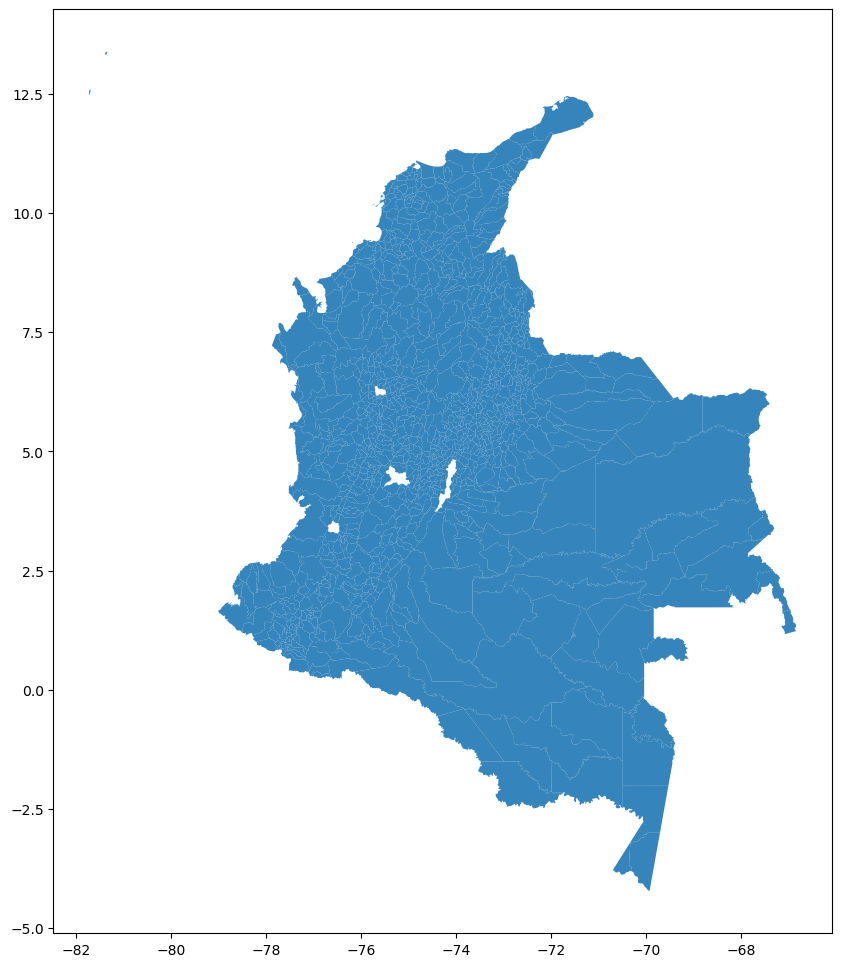

In [27]:
gdf_filtrado.plot(figsize=(12,12), alpha=0.9)

In [28]:
gdf_filtrado.shape

(1117, 5)

## Análisis de las métricas estadísticas
Iniciamos el proceso de entendimiento de los datos mediante la revisión de las principales métricas estadísticas del conjunto de datos. A partir de esta exploración, evidenciamos los siguientes comportamientos:

**Total de hogares (TOTAL_HOGA)**
- Se observa un valor máximo de 260.220 hogares, equivalente a aproximadamente 36 veces el valor del percentil 75 (7.233 hogares). Esta diferencia evidencia una importante separación en la parte superior de la distribución y sugiere la presencia de municipios con una concentración considerablemente mayor de hogares.
- La media (8.631 hogares) y la mediana (3.568 hogares) presentan una diferencia significativa. La media supera aproximadamente 2,42 veces la mediana, lo que evidencia una distribución asimétrica hacia la derecha, posiblemente influenciada por municipios de gran tamaño poblacional.
- La desviación estándar equivale aproximadamente al 233,2 % de la media, lo que refleja una dispersión muy elevada de los datos y una marcada heterogeneidad entre los municipios.
- Las diferencias entre los percentiles 25, 50 y 75 son de 1.639 y 3.665 hogares, respectivamente. Esto evidencia una mayor dispersión en el tramo superior de la distribución.
  
**Hogares con déficit cuantitativo (Num_Hogares_Deficit_Cuanti)***
- Se registra un valor máximo de 26.804 hogares, equivalente a aproximadamente 22,3 veces el valor del percentil 75 (1.203 hogares). Esta diferencia sugiere una importante concentración de hogares con déficit cuantitativo en determinados municipios y la posible presencia de observaciones extremas.
- La media (1.104 hogares) y la mediana (404 hogares) presentan una diferencia considerable. La media equivale aproximadamente a 2,73 veces la mediana, lo que refleja una distribución asimétrica hacia la derecha.
- La desviación estándar representa aproximadamente el 195,2 % de la media, lo que evidencia una dispersión elevada y diferencias importantes en la magnitud del déficit entre municipios.
- Las diferencias entre los percentiles 25, 50 y 75 son de 275 y 799 hogares, respectivamente. Esto indica una mayor dispersión en el tramo superior de la distribución, donde se encuentran los municipios con mayores cantidades de hogares en déficit.

**Longitud de la geometría (Longitud_geometry)**
- Se observa un valor máximo de 20,046, equivalente a aproximadamente 12,1 veces el valor del percentil 75 (1,656). Esta diferencia sugiere la presencia de municipios con perímetros considerablemente superiores al comportamiento habitual del conjunto.
- La media (1,480) y la mediana (0,971) presentan cierta diferencia, lo que evidencia una posible asimetría positiva en la distribución.
- La desviación estándar equivale aproximadamente al 114,9 % de la media, lo que refleja una dispersión considerable entre las dimensiones geométricas de los municipios.
- Las diferencias entre los percentiles 25, 50 y 75 son de 0,358 y 0,685, respectivamente. Esto evidencia una mayor dispersión en el tramo superior de la distribución.

**Área de la geometría (Area_geometry)**
- Se registra un valor máximo de 5,309, equivalente a aproximadamente 92,7 veces el valor del percentil 75 (0,0573). Esta diferencia evidencia una marcada separación en la parte superior de la distribución y sugiere la presencia de municipios con extensiones territoriales considerablemente mayores.
- La media (0,0828) supera aproximadamente 3,53 veces la mediana (0,0235), lo que refleja una distribución fuertemente asimétrica hacia la derecha.
- La desviación estándar representa aproximadamente el 313,6 % de la media, lo que evidencia una dispersión muy elevada en las extensiones territoriales municipales.
- Las diferencias entre los percentiles 25, 50 y 75 son de 0,0127 y 0,0338, respectivamente. Esto refleja una mayor dispersión en el tramo superior de la distribución.

In [29]:
gdf_filtrado.describe().T

,count,mean,std,min,25%,50%,75%,max
TOTAL_HOGA,1117.0,8630.837959,20118.202987,29.000000,1929.000000,3568.000000,7233.000000,260220.000000
Num_Hogares_Deficit_Cuanti,1117.0,1103.615040,2154.731296,4.000000,129.000000,404.000000,1203.000000,26804.000000
Longitud_geometry,1117.0,1.479703,1.700220,0.172962,0.613251,0.970994,1.656029,20.045859
Area_geometry,1117.0,0.082811,0.259699,0.001293,0.010796,0.023480,0.057281,5.308580


A partir de las métricas estadísticas revisadas, podemos establecer las siguientes conclusiones:
- Las variables TOTAL_HOGA y Num_Hogares_Deficit_Cuanti presentan una elevada heterogeneidad entre municipios. En ambos casos, la media supera considerablemente la mediana y los valores máximos se encuentran muy alejados del percentil 75, lo que evidencia una distribución asimétrica y una posible influencia de municipios de gran tamaño.
- El déficit cuantitativo presenta un comportamiento similar al total de hogares en términos de dispersión y asimetría. Sin embargo, su mayor interés para el proyecto radica en que permite identificar municipios con necesidades potenciales de vivienda nueva, tanto en términos absolutos como relativos.
- Las variables geométricas también presentan distribuciones asimétricas hacia la derecha. Particularmente, Area_geometry registra una diferencia muy pronunciada entre el valor máximo y el percentil 75, lo que evidencia diferencias importantes en la extensión territorial de los municipios.
- La variable Area_geometry presenta la mayor dispersión relativa, con una desviación estándar equivalente al 313,6 % de su media. Por su parte, TOTAL_HOGA registra una dispersión relativa del 233,2 %, seguida del déficit cuantitativo, con un 195,2 %.
- En las cuatro variables, la distancia entre los percentiles 50 y 75 supera la distancia entre los percentiles 25 y 50. Esto sugiere una mayor dispersión de los valores por encima de la mediana.

In [30]:
gdf_filtrado["Porcentaje_Deficit_Cuantitativo"] = (gdf_filtrado["Num_Hogares_Deficit_Cuanti"] /gdf_filtrado["TOTAL_HOGA"]) * 100

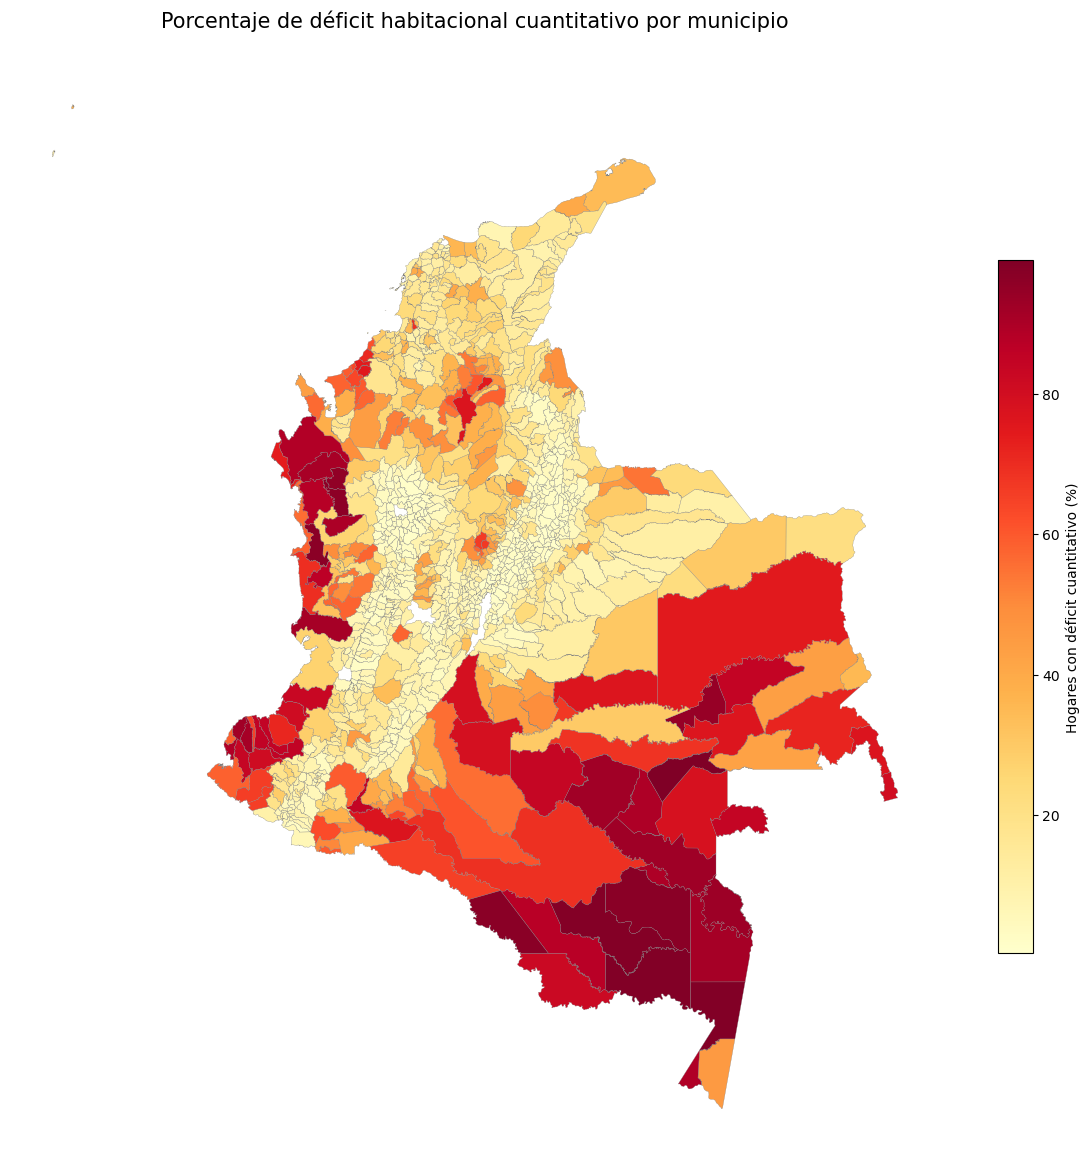

In [31]:
fig, ax = plt.subplots(figsize=(15, 15))

gdf_filtrado.plot(
    column="Porcentaje_Deficit_Cuantitativo",
    cmap="YlOrRd",
    linewidth=0.2,
    edgecolor="gray",
    legend=True,
    legend_kwds={
        "label": "Hogares con déficit cuantitativo (%)",
        "orientation": "vertical",
        "shrink": 0.6
    },
    missing_kwds={
        "color": "lightgray",
        "label": "Sin información"
    },
    ax=ax
)

ax.set_title(
    "Porcentaje de déficit habitacional cuantitativo por municipio",
    fontsize=15,
    pad=20
)

ax.set_axis_off()

plt.show()

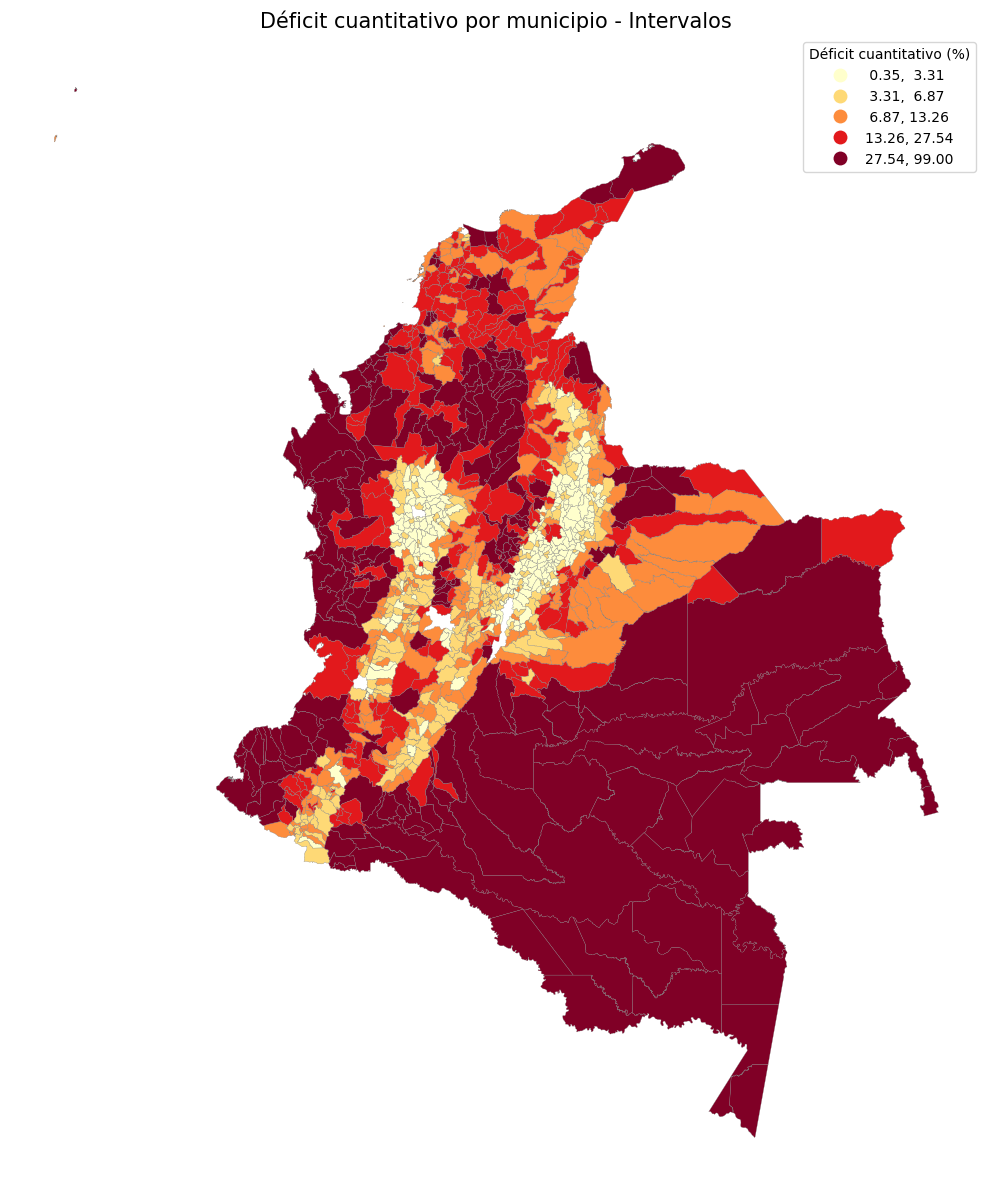

In [32]:
fig, ax = plt.subplots(figsize=(15, 15))

gdf_filtrado.plot(
    column="Porcentaje_Deficit_Cuantitativo",
    cmap="YlOrRd",
    scheme="Quantiles",
    k=5,
    linewidth=0.2,
    edgecolor="gray",
    legend=True,
    legend_kwds={"title": "Déficit cuantitativo (%)"},
    ax=ax
)

ax.set_title("Déficit cuantitativo por municipio - Intervalos", fontsize=15)
ax.set_axis_off()

plt.show()

A partir de los mapas, podemos destacar los siguientes comportamientos:

- Región Andina: se observa una importante heterogeneidad entre municipios. En buena parte del territorio andino predominan tonalidades claras, que representan menores porcentajes de déficit. Sin embargo, también aparecen municipios con valores intermedios y elevados, lo que evidencia diferencias importantes dentro de una misma región.

- Región Pacífica: se identifican varios municipios con porcentajes elevados de déficit cuantitativo, especialmente hacia el litoral. Este comportamiento sugiere una mayor incidencia relativa de las necesidades habitacionales en determinados territorios de esta región.

- Región Caribe: presenta un comportamiento heterogéneo, con municipios que registran porcentajes bajos, intermedios y elevados. No se observa una distribución completamente uniforme del fenómeno.

- Regiones de la Orinoquía y Amazonía: se identifican diferencias importantes entre municipios. Algunos territorios presentan porcentajes elevados, mientras que otros registran valores considerablemente menores. Es importante tener presente que las grandes extensiones territoriales de estas regiones no necesariamente representan una mayor concentración de hogares con déficit.


A partir de la distribución espacial observada, podemos establecer las siguientes conclusiones:
- El déficit cuantitativo presenta una marcada heterogeneidad geográfica. Los municipios con mayores porcentajes no se concentran exclusivamente en una región, sino que aparecen distribuidos en diferentes zonas del país.
- La región Andina presenta una mayor diversidad de comportamientos entre municipios, con territorios de baja, media y alta incidencia del déficit habitacional.
- Se identifican municipios de la región Pacífica y de otras zonas periféricas con porcentajes elevados de déficit, lo que permite reconocer territorios donde las necesidades habitacionales tienen una mayor incidencia relativa.
- La distribución espacial evidencia que el tamaño territorial de los municipios no determina necesariamente la magnitud del déficit. Por esta razón, resulta importante diferenciar entre la extensión geográfica, la cantidad de hogares afectados y la proporción que representan sobre el total de hogares.
- Los municipios con porcentajes elevados constituyen territorios de interés para profundizar en el análisis de necesidades habitacionales. Sin embargo, estos resultados no permiten concluir por sí solos que sean mercados atractivos para el desarrollo de proyectos inmobiliarios.

In [33]:
df_analisis = gdf_filtrado.copy()

columnas_numericas = ["TOTAL_HOGA","Num_Hogares_Deficit_Cuanti","Longitud_geometry","Area_geometry","Porcentaje_Deficit_Cuantitativo"]

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


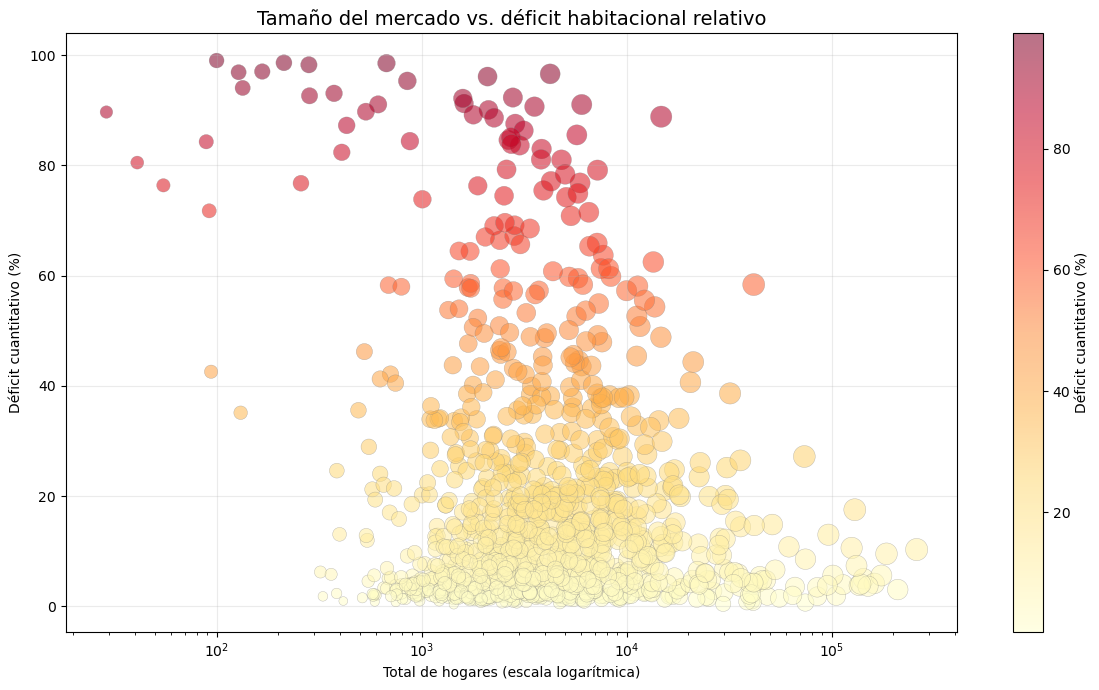

In [34]:
fig, ax = plt.subplots(figsize=(12, 7))

tamanos = (
    np.log1p(df_analisis["Num_Hogares_Deficit_Cuanti"]) * 25
)

scatter = ax.scatter(
    df_analisis["TOTAL_HOGA"],
    df_analisis["Porcentaje_Deficit_Cuantitativo"],
    s=tamanos,
    c=df_analisis["Porcentaje_Deficit_Cuantitativo"],
    cmap="YlOrRd",
    alpha=0.55,
    edgecolors="gray",
    linewidths=0.3
)

ax.set_xscale("log")

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Déficit cuantitativo (%)")

ax.set_title(
    "Tamaño del mercado vs. déficit habitacional relativo",
    fontsize=14
)

ax.set_xlabel("Total de hogares (escala logarítmica)")
ax.set_ylabel("Déficit cuantitativo (%)")

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

Se observa una concentración importante de municipios en el rango inferior del porcentaje de déficit cuantitativo, principalmente por debajo del 20 %. Esto indica que, para una proporción considerable de municipios, la incidencia relativa del déficit es relativamente baja.



Los municipios con mayor cantidad de hogares se concentran principalmente en la parte inferior del gráfico. Esto evidencia que un mercado habitacional de mayor tamaño no implica necesariamente una mayor proporción de hogares con déficit cuantitativo.



Se identifican municipios con porcentajes de déficit superiores al 60 %, e incluso cercanos al 100 %, aunque presentan tamaños de mercado considerablemente menores. Esto sugiere que existen territorios donde el déficit tiene una incidencia elevada, pero cuya escala de mercado es más reducida.



Las burbujas de mayor tamaño se concentran principalmente en municipios con mercados habitacionales amplios y porcentajes de déficit bajos e intermedios. Esto indica que algunos municipios pueden concentrar cantidades importantes de hogares afectados incluso cuando su incidencia relativa no es particularmente elevada.



La distribución evidencia una importante heterogeneidad entre municipios, tanto en el tamaño del mercado como en la incidencia del déficit. Por tanto, resulta necesario considerar conjuntamente las magnitudes absolutas y relativas para identificar territorios de interés.

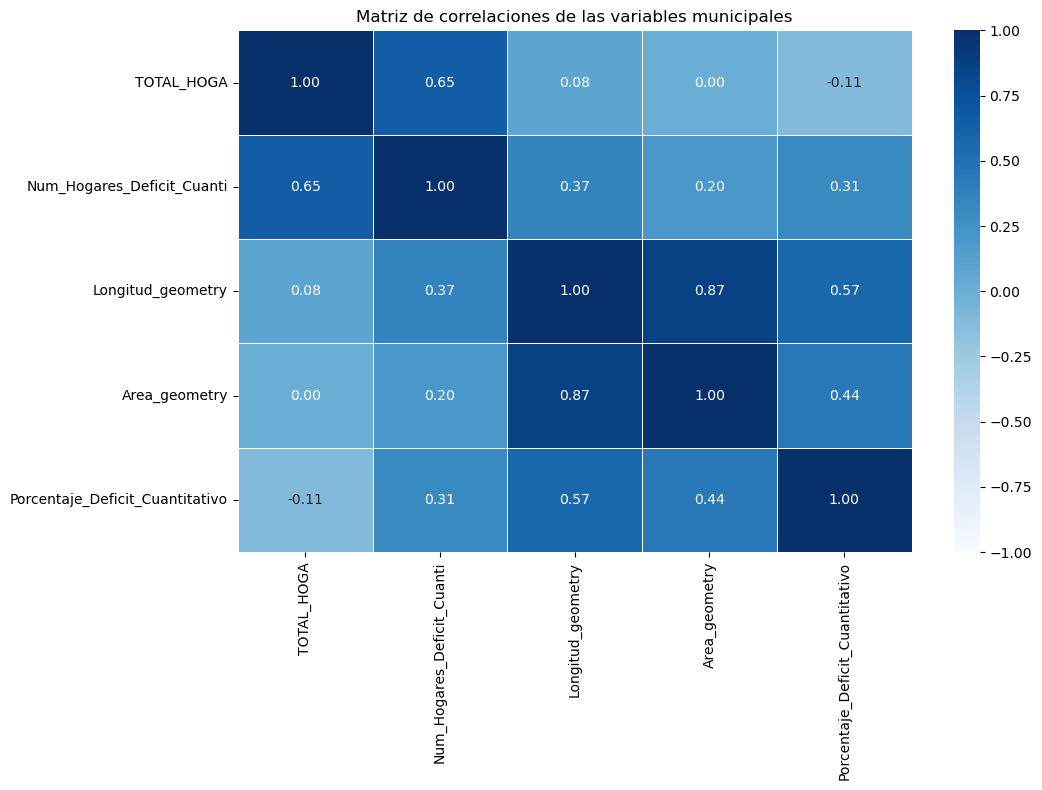

In [35]:
matriz_corr = df_analisis[columnas_numericas].corr(method="pearson")

plt.figure(figsize=(11, 8))

sns.heatmap(matriz_corr,annot=True,cmap="Blues",fmt=".2f",linewidths=0.5,vmin=-1,vmax=1,center=0)

plt.title("Matriz de correlaciones de las variables municipales")
plt.tight_layout()
plt.show()

Se observa una correlación positiva moderadamente alta. Esto indica que los municipios con mayor cantidad de hogares tienden a registrar también un mayor número absoluto de hogares con déficit cuantitativo. Este comportamiento es coherente con la relación entre el tamaño del mercado habitacional y la cantidad de hogares afectados.

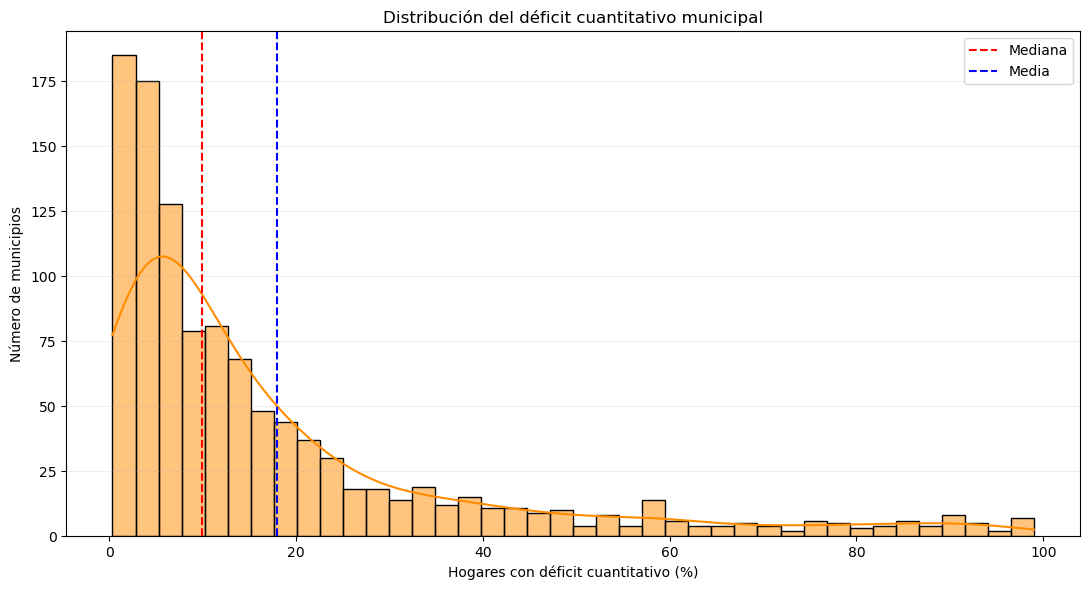

In [36]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.histplot(
    data=df_analisis,
    x="Porcentaje_Deficit_Cuantitativo",
    bins=40,
    kde=True,
    color="darkorange",
    edgecolor="black",
    ax=ax
)

ax.axvline(
    df_analisis["Porcentaje_Deficit_Cuantitativo"].median(),
    color="red",
    linestyle="--",
    label="Mediana"
)

ax.axvline(
    df_analisis["Porcentaje_Deficit_Cuantitativo"].mean(),
    color="blue",
    linestyle="--",
    label="Media"
)

ax.set_title("Distribución del déficit cuantitativo municipal")
ax.set_xlabel("Hogares con déficit cuantitativo (%)")
ax.set_ylabel("Número de municipios")

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

A partir de la distribución observada, podemos destacar los siguientes comportamientos:
- Se evidencia una concentración importante de municipios en los intervalos inferiores al 20 % de déficit cuantitativo. Esto indica que una proporción considerable de los municipios presenta una incidencia relativamente baja del déficit habitacional.
- La distribución presenta una marcada asimetría positiva, caracterizada por una cola prolongada hacia los valores superiores. Se identifican municipios con porcentajes de déficit que alcanzan valores cercanos al 100 %, aunque su frecuencia es considerablemente menor.
- La media (aproximadamente 17,7 %) se encuentra por encima de la mediana (aproximadamente 9,7 %). Esta diferencia evidencia que los municipios con porcentajes elevados de déficit influyen en el incremento del promedio general.
- La mayor frecuencia de observaciones se concentra en los primeros intervalos de la distribución, especialmente por debajo del 10 %. A medida que aumenta el porcentaje de déficit, disminuye progresivamente la cantidad de municipios.
- Se observa una dispersión considerable entre los municipios, lo que refleja diferencias importantes en la incidencia del déficit cuantitativo a nivel territorial.

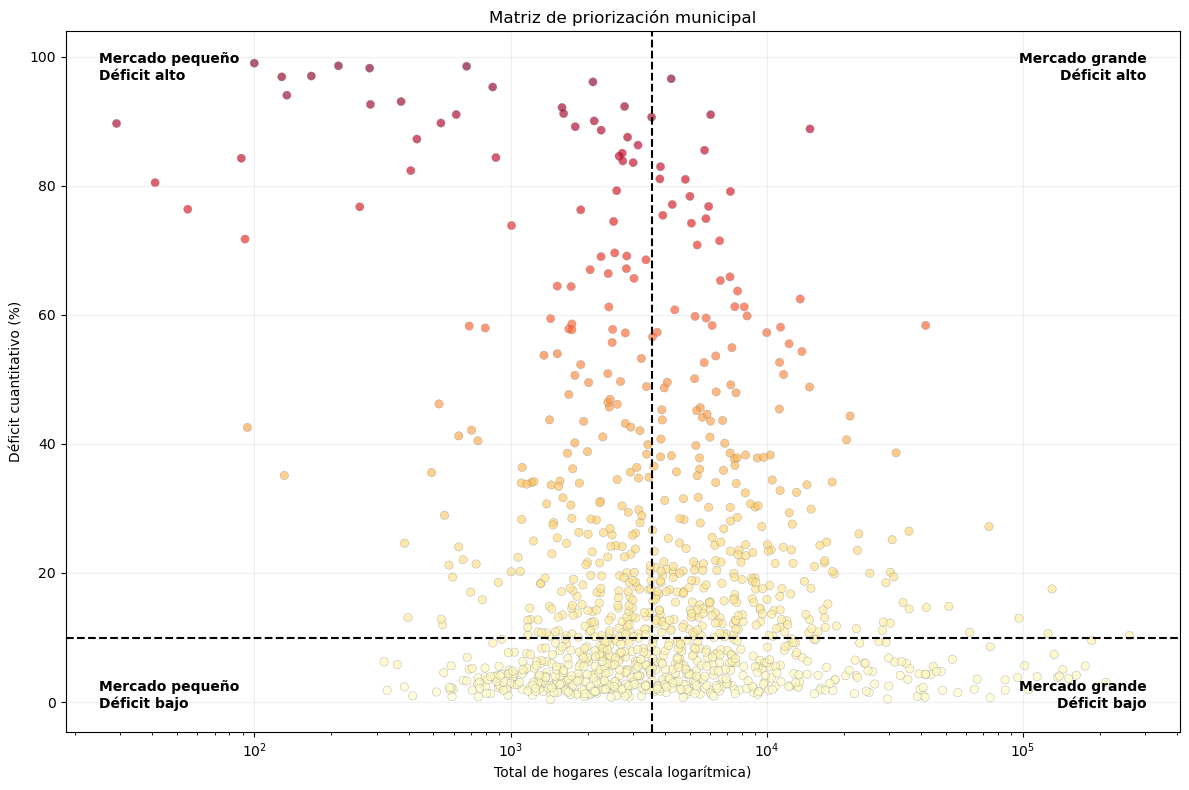

In [37]:
mediana_hogares = df_analisis["TOTAL_HOGA"].median()

mediana_deficit = df_analisis[
    "Porcentaje_Deficit_Cuantitativo"
].median()

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    df_analisis["TOTAL_HOGA"],
    df_analisis["Porcentaje_Deficit_Cuantitativo"],
    c=df_analisis["Porcentaje_Deficit_Cuantitativo"],
    cmap="YlOrRd",
    alpha=0.65,
    edgecolors="gray",
    linewidths=0.3
)

ax.set_xscale("log")

ax.axvline(mediana_hogares, color="black", linestyle="--")
ax.axhline(mediana_deficit, color="black", linestyle="--")

ax.text(
    0.97, 0.97,
    "Mercado grande\nDéficit alto",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontweight="bold"
)

ax.text(
    0.03, 0.97,
    "Mercado pequeño\nDéficit alto",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontweight="bold"
)

ax.text(
    0.97, 0.03,
    "Mercado grande\nDéficit bajo",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontweight="bold"
)

ax.text(
    0.03, 0.03,
    "Mercado pequeño\nDéficit bajo",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontweight="bold"
)

ax.set_title("Matriz de priorización municipal")
ax.set_xlabel("Total de hogares (escala logarítmica)")
ax.set_ylabel("Déficit cuantitativo (%)")

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

A partir de la distribución observada, podemos destacar los siguientes comportamientos:
- Mercado pequeño y déficit bajo: concentra una proporción importante de los municipios. Se observa una acumulación de observaciones por debajo de la mediana del total de hogares y con porcentajes de déficit inferiores al 10 %. Esto evidencia que gran parte de los municipios presenta simultáneamente una escala de mercado reducida y una incidencia relativamente baja del déficit habitacional.
- Mercado pequeño y déficit alto: se identifica un conjunto de municipios con porcentajes de déficit considerablemente elevados, algunos cercanos al 100 %, pero con cantidades relativamente reducidas de hogares. Estos territorios presentan una incidencia importante de necesidades habitacionales, aunque su tamaño de mercado podría limitar la escala de los proyectos inmobiliarios.
- Mercado grande y déficit bajo: se observan municipios con cantidades elevadas de hogares, pero porcentajes de déficit relativamente reducidos. Estos territorios representan mercados habitacionales de mayor tamaño, aunque la incidencia del déficit cuantitativo no es particularmente elevada.
- Mercado grande y déficit alto: se identifica un grupo más reducido de municipios que combina una cantidad de hogares superior a la mediana y porcentajes elevados de déficit cuantitativo. Estos territorios merecen especial atención, dado que presentan simultáneamente una escala de mercado importante y una mayor incidencia de necesidades habitacionales.

In [38]:
condiciones = [
    (df_analisis["TOTAL_HOGA"] >= mediana_hogares) &
    (df_analisis["Porcentaje_Deficit_Cuantitativo"] >= mediana_deficit),

    (df_analisis["TOTAL_HOGA"] < mediana_hogares) &
    (df_analisis["Porcentaje_Deficit_Cuantitativo"] >= mediana_deficit),

    (df_analisis["TOTAL_HOGA"] < mediana_hogares) &
    (df_analisis["Porcentaje_Deficit_Cuantitativo"] < mediana_deficit),

    (df_analisis["TOTAL_HOGA"] >= mediana_hogares) &
    (df_analisis["Porcentaje_Deficit_Cuantitativo"] < mediana_deficit)
]

categorias = [
    "Mercado grande - Déficit alto",
    "Mercado pequeño - Déficit alto",
    "Mercado pequeño - Déficit bajo",
    "Mercado grande - Déficit bajo"
]

df_analisis["Segmento_Municipal"] = np.select(
    condiciones,
    categorias,
    default="Sin clasificación"
)

print(df_analisis["Segmento_Municipal"].value_counts())

Segmento_Municipal
Mercado grande - Déficit alto     299
Mercado pequeño - Déficit bajo    298
Mercado grande - Déficit bajo     260
Mercado pequeño - Déficit alto    260
Name: count, dtype: int64


Mercado grande - Déficit alto (299 municipios): constituye el segmento más numeroso, con el 26,77 % del total. Estos municipios combinan una cantidad de hogares superior a la mediana y una incidencia relativamente elevada del déficit cuantitativo. Representan un grupo prioritario para profundizar en la evaluación de oportunidades inmobiliarias.



Mercado pequeño - Déficit bajo (298 municipios): representa el 26,68 %. Son municipios con menor escala habitacional y menor incidencia del déficit. En principio, presentan menor prioridad dentro del objetivo de identificar mercados potenciales.



Mercado grande - Déficit bajo (260 municipios): concentra el 23,28 %. Estos territorios cuentan con una base considerable de hogares, aunque presentan una incidencia relativamente baja del déficit. Es importante evaluarlos desde la perspectiva de la dinámica inmobiliaria, la competencia y la oferta disponible.



Mercado pequeño - Déficit alto (260 municipios): también representa el 23,28 %. Son territorios donde el déficit tiene una incidencia elevada, pero el tamaño del mercado es relativamente reducido. Su análisis podría ser interesante para identificar oportunidades específicas, aunque se debe evaluar cuidadosamente la escala comercial.